In [191]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"

In [192]:
from scipy.optimize import brute

In [237]:
class BB_BackTester():
    '''Bollinger Band Back Tester Class

    Attributes:
    ===========
    symbol : ticker of the instrument for the trading
    df: pd.DataFrame
        the dataframe within the closing price of the instrument.
    start: str
        start date of the trading. format: "YYYY-MM-DD"
    end: str
        end date of the trading, format: "YYYY-MM-DD"
    SMA : int
        Simple Moving Average
    std: int
        Standard Deviation (2 or 3)
    tc: float
        ptoportinal trading cost.
    
    std: int (2 or 3)
        it will be used to compute the upper and the lower bands for the trading strategy.

    Methods:
    ========
    get_data():
    trading_strategy():
    set_parametrs():
    optimized_parameter_finder():
    plot_results()
    '''
    def __init__(self , symbol : str , df : pd.DataFrame , start : str , end : str , SMA : int , tc : float , std : int):
        self.symbol = symbol
        self.df = df
        self.start = start
        self.end = end
        self.SMA = SMA
        self.std = std
        self.tc = tc
        ###############################
        self.data = None
        self.results = None
        self.KPI = None
        self.KPI_table = None
        self.get_data()
    def __repr__(self) -> str:
        return (
            f"BB_BackTester(symbol : {self.symbol} | start : {self.start} | end : {self.end} | "
            f"simple moving average : {self.SMA} | std : {self.std} | trading cost : {self.tc}"
                )

    def get_data(self):

        raw = self.df.loc[self.start : self.end].copy()
        raw.columns = ["price"]
        raw["SMA"] = raw["price"].rolling(window=self.SMA).mean()
        raw["Lower_Band"] = raw["SMA"] - raw["price"].rolling(window=self.SMA).std() * self.std
        raw["Upper_Band"] = raw["SMA"] + raw["price"].rolling(window = self.SMA).std() * self.std
        raw = raw.dropna()
        # Check if data is empty after dropping NaN 
        if raw.empty:
            raise ValueError(f"No valid data remaining after calculating indicators for {self.symbol}. Check your data and parameter.")
        
        self.data = raw
        return raw

    def trading_strategy(self , displaying_mode = None):
        '''trading strategy implemented by the stochastic oscillator strategy 
           comparasion with the buy&hold strategy.
        
        Parameters:
        ===========
        displaying_mode : str , optional
            'tabular' : returns styled KPI table.
            'value' : return the single value: the performance of our trading strategy.
        '''
        data = self.data.copy()

        #Generate the trading signals:
        data["distance"] = data["price"] - data["SMA"]
        
        data["position"] = np.where(data["price"] > data["Lower_Band"] , +1 ,  np.nan) # 1. OverSold -> go long
        data["position"] = np.where(data["price"] < data["Upper_Band"] , -1 , data["position"]) # 2. OverBought -> go short
        data["position"] = np.where(data["distance"] * data["distance"].shift(+1) <0 , 0 , data["position"])  # 3. crossing SMA ("Middle Band") -> go neutral
        data["position"] = data["position"].ffill().fillna(value = 0) # 4. where 1-3 isn´t applicable -> hold previous position
        data["trades"] = data["position"].diff().fillna(value=0).abs()

        data["log_ret"] = np.log(data["price"]/data["price"].shift(1)) # Buy & Hold Strategy's return
        data["strategy_ret"] = data["log_ret"] * data["position"].shift(1) # Bollinger Band Strategy's return
        data["strategy_ret_net"] = data["strategy_ret"] - data["trades"] * self.tc
        
        # Claculate cumulative returns:
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum())
        data["cum_strategy_ret"] = np.exp(data["strategy_ret"].cumsum())
        data["cum_strategy_ret_net"] = np.exp(data["strategy_ret_net"].cumsum())
        data = data.dropna()

        if data.empty:
            raise ValueError(f"No Valid data remaining after generating the trading signals for {self.symbol}.")
        self.results = data

        # Extract final performance value:
        strategy_performance = data["cum_strategy_ret"].iloc[-1]
        buy_and_hold_performance = data["cum_log_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance

        self.KPI = pd.DataFrame(
            {
                "Bollinger_Band Strategy" : strategy_performance ,
                "Buy & Hold" : buy_and_hold_performance , 
                "Out Performance" : out_performance ,
                "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252 , 
                "Ann. Return BB Strategy" :  data["strategy_ret"].mean() * 252 ,
                "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252) ,
                "Ann. Risk BB Strategy" : np.sqrt(data["strategy_ret"].var() * 252)
            },
            index = [f"Bollinger Band: symbol : {self.symbol} | SMA : {self.SMA} | STD : {self.std}"]
        )
        self.KPI.index.name = "Performance"
        self.KPI_table = self.KPI.T.style.format("{:.2%}")

        if displaying_mode == "tabular":
            return self.KPI_table
        elif displaying_mode == "value":
            return float(strategy_performance)
        else: 
            print("Display mode not specified.")
            return None

    def set_parameters(self , new_SMA = None , new_STD = None):
        '''
        '''
        if self.df is None or self.df.empty:
            raise AttributeError("Data not Loaded. Call get_data() first")
        new_raw = self.df.loc[self.start : self.end].copy()

        if new_SMA is not None:
            self.SMA = int(new_SMA)
        if new_STD is not None:
            self.std = int(new_STD)

        # new_raw["SMA"] = new_raw["price"].rolling(window=self.SMA)
        # new_raw["Lower_Band"] = new_raw["SMA"] - new_raw["price"].rolling(window=self.SMA).std() * self.std
        # new_raw["Upper_Band"] = new_raw["SMA"] + new_raw["price"].rolling(window=self.SMA).std() * self.std
        # new_raw = new_raw.dropna()

        # if new_raw is None or new_raw.empty:
        #     raise ValueError(f"No valid data remaining after calculating indicators for {self.symbol}. Check your data and parameter.")

        # self.data = new_raw


    def optimized_parameter_finder(self , SMA_ranges : tuple , STD_ranges : tuple):
        '''
        grid search algorithm using the brute function to find the maximum value of the strategy return  
        Parameters:
        ===========
        SMA_ranges: (start , stop , step)
        it is a range for SMA (Simple Moving Average)

        STD_ranges: (2 , 3 + 1 , 1)
        it is the range (2,3) for the standard      
        '''
        def objective_function(x):
            try:
                self.set_parameters(x[0] , x[1])
                self.get_data()
                val = self.trading_strategy(displaying_mode="value")
                return -val
            except Exception as e:
                # Return a large penalty value if optimization fails.
                return 1e10

        print("Starting optimization ... This may take time depending on the range size.")
        res = brute(func = objective_function , ranges = (SMA_ranges , STD_ranges) , finish = None)
        best_SMA = int(res[0])
        best_std = int(res[1])
        print(f"Optimal Parameters found : SMA : {best_SMA} | std : {best_std}.")

        # Set optimal parameters and run final strategy
        self.set_parameters(new_SMA = best_SMA , new_STD=best_std)
        return self.trading_strategy(displaying_mode="tabular")

    def plot_results(self , plot_name = None):
        '''
        plot_name : str , optional
        'Bollinger_Band' : it plots Bollinger Bands, Price, and SMA.
        'position' : it plots all the positions related to the trading strategy.
        'Bollinger_Band_Position' : it is the combination of Bollinger_Band & positions.
        'trading_strategy': it plots the performance of the trading strategy (net) versus the buy&hold strategy.
        '''
        if plot_name == "Bollinger_Band":
            fig , ax = plt.subplots(figsize = (16,6))
            ax.plot(self.data["price"], label = f"price" , lw = 1 , color = "dimgray")
            ax.plot(self.data["SMA"], label = f"SMA ({self.SMA})" , lw = 2.5 , ls = ":" )
            ax.plot(self.data["Lower_Band"] , label = f"Lower Band" , lw = 2.5 , ls = "-", color ="green" )
            ax.plot(self.data["Upper_Band"] , label = f"Upper Band" , lw = 2.5 , ls = "-" , color = "red")
            ax.fill_between(y1 = self.data["Lower_Band"] , y2 = self.data["Upper_Band"] , x = self.data["price"].index , color = "cornsilk")
            ax.set_title(f"{self.symbol}: Bollinger Band | Price | SMA ({self.SMA})")
            fig.gca().spines[["top" , "right"]].set_visible(False)
            ax.set_ylabel("Volatility")
            ax.autoscale(enable = True , axis ="x" , tight = True)
            ax.legend(loc = (0 , 1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
            ax.grid(axis ="y" , alpha = .6)
            plt.show()

        elif plot_name == "position":
            fig , ax = plt.subplots(figsize = (16,6))
            ax.plot(self.results["position"] , label = "position" , color = "darkviolet" , ls = "--")
            ax.set_title(f"{self.symbol}: Positions for Bollinger Band Trading Strategy")
            ax.set_ylabel("positions" , color = "darkviolet")
            ax.set_yticks(ticks= [ -1 , 0 , 1])
            ax.set_yticklabels(labels = ["Buying" , "Neutral" , "Selling"])
            for label in ax.get_yticklabels():
                if label.get_text() == "Selling":
                    label.set_color("red")
                elif label.get_text() == "Neutral":
                    label.set_color("dimgray")
                else:
                    label.set_color("green")
            ax.autoscale(enable = True , axis ="x" , tight = True)
            ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
            ax.grid(axis ="y" , alpha = .6)
            fig.gca().spines[["top" , "right"]].set_visible(False)
            plt.show()

        elif plot_name == "Bollinger_Band_Position":
            fig , ax = plt.subplots(figsize = (12,4))
            ax.plot(self.results["price"] , label = f"price" , lw = 2 , color = "dimgray")
            ax.plot(self.results["SMA"] , label = f"SMA ({self.SMA})" , lw = 2.5 , ls = ":" )
            ax.plot(self.results["Lower_Band"] , label = f"Lower Band" , lw = 2.5 , ls = "-", color ="green" )
            ax.plot(self.results["Upper_Band"] , label = f"Upper Band" , lw = 2.5 , ls = "-" , color = "red")
            ax.fill_between(y1 = self.results["Lower_Band"] , y2 = self.results["Upper_Band"] , x = self.results["price"].index , color = "cornsilk")
            ax.set_title(f"{self.symbol}: Bollinger Band | Price | SMA ({self.SMA})")
            fig.gca().spines[["top" , "right"]].set_visible(False)
            ax.set_ylabel("Volatility")
            ax.autoscale(enable = True , axis ="x" , tight = True)
            ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")


            ax2 = ax.twinx()
            ax2.plot(self.results["position"] , label = f"position" , lw = 2 , ls = "-." , color = "darkviolet")
            ax2.set_ylabel("Position" , color = "darkviolet")
            ax2.set_yticks(ticks = [-1 , 0 , +1])
            ax2.set_yticklabels(labels = ["Buying" , "Neutral" , "Selling"])
            ax2.autoscale(enable = True , axis ="x" , tight = True)
            ax2.legend(loc = (.89,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
            ax2.grid(axis ="y" , alpha = .6)
            fig.gca().spines[["top" , "right"]].set_visible(False)
            for ticker in ax2.get_yticklabels():
                if ticker.get_text() == "Selling":
                    ticker.set_color("red")
                elif ticker.get_text() == "Neutral":
                    ticker.set_color("dimgray")
                else:
                    ticker.set_color("green")
            plt.show()

        elif plot_name == "trading_strategy":
            fig , ax = plt.subplots(figsize = (12,4))
            ax.plot(self.results["cum_log_ret"] , label = "Buy&Hold")
            ax.plot(self.results["cum_strategy_ret"] , label = "Bollinger Band Strategy")
            ax.plot(self.results["cum_strategy_ret_net"] , label = "Bollinger Band Strategy (Net)")
            ax.set_title(f"{self.symbol}: Trading Strategies Performance Comparasion")
            ax.autoscale(enable = True , axis ="x" , tight = True)
            ax.legend(loc = (0,1.1) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
            ax.grid(axis = "y")
            fig.gca().spines[["top" , "right"]].set_visible(False)
            plt.show()

        else:
            print("plot name is not specified. Please select if from: \nBollinger_Band , position , Bollinger_Band_Position , trading_strategy")
            return None

        



In [238]:
df = pd.read_csv("intraday.csv", parse_dates = ["time"], index_col = "time")
df

,price
time,
2018-01-01 22:00:00+00:00,1.201205
2018-01-02 04:00:00+00:00,1.207055
2018-01-02 10:00:00+00:00,1.204440
2018-01-02 16:00:00+00:00,1.205800
2018-01-02 22:00:00+00:00,1.204690
...,...
2019-12-29 22:00:00+00:00,1.119920
2019-12-30 04:00:00+00:00,1.119940
2019-12-30 10:00:00+00:00,1.120095


In [239]:
bb_tester = BB_BackTester(symbol = "EURUSD=X", df = df , start = "2018-01-01" , end = "2019-12-30" , SMA = 30 , std = 2 , tc = 0.0007)

In [240]:
bb_tester

BB_BackTester(symbol : EURUSD=X | start : 2018-01-01 | end : 2019-12-30 | simple moving average : 30 | std : 2 | trading cost : 0.0007

In [241]:
bb_tester.get_data()

,price,SMA,Lower_Band,Upper_Band
time,,,,
2018-01-11 04:00:00+00:00,1.194770,1.200504,1.190849,1.210160
2018-01-11 10:00:00+00:00,1.204915,1.200628,1.190841,1.210415
2018-01-11 16:00:00+00:00,1.203205,1.200500,1.190964,1.210035
2018-01-11 22:00:00+00:00,1.205165,1.200524,1.190943,1.210104
2018-01-12 04:00:00+00:00,1.212530,1.200748,1.190374,1.211122
...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,1.111391,1.105215,1.117567
2019-12-30 04:00:00+00:00,1.119940,1.111553,1.104754,1.118352
2019-12-30 10:00:00+00:00,1.120095,1.111777,1.104318,1.119235


In [242]:
bb_tester.trading_strategy(displaying_mode="tabular")

Performance,Bollinger Band: symbol : EURUSD=X | SMA : 30 | STD : 2
Bollinger_Band Strategy,108.31%
Buy & Hold,93.77%
Out Performance,14.54%
Ann. Return Buy & Hold,-0.79%
Ann. Return BB Strategy,0.99%
Ann. Risk Buy & Hold,3.00%
Ann. Risk BB Strategy,2.88%


In [243]:
bb_tester.trading_strategy(displaying_mode="value")

1.0830909611852564

In [244]:
bb_tester.set_parameters(new_SMA=40 , new_STD=3)

In [245]:
bb_tester.get_data()

,price,SMA,Lower_Band,Upper_Band
time,,,,
2018-01-15 16:00:00+00:00,1.226365,1.204346,1.177165,1.231527
2018-01-15 22:00:00+00:00,1.225730,1.204959,1.176000,1.233918
2018-01-16 04:00:00+00:00,1.223320,1.205366,1.175136,1.235596
2018-01-16 10:00:00+00:00,1.222960,1.205829,1.174474,1.237184
2018-01-16 16:00:00+00:00,1.226070,1.206336,1.173544,1.239127
...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,1.112137,1.102934,1.121339
2019-12-30 04:00:00+00:00,1.119940,1.112185,1.102660,1.121709
2019-12-30 10:00:00+00:00,1.120095,1.112348,1.102127,1.122570


In [246]:
bb_tester.trading_strategy(displaying_mode="tabular")

Performance,Bollinger Band: symbol : EURUSD=X | SMA : 40 | STD : 3
Bollinger_Band Strategy,106.31%
Buy & Hold,91.36%
Out Performance,14.96%
Ann. Return Buy & Hold,-1.12%
Ann. Return BB Strategy,0.76%
Ann. Risk Buy & Hold,2.97%
Ann. Risk BB Strategy,2.85%


In [247]:
bb_tester.optimized_parameter_finder(SMA_ranges=(1,70,1) , STD_ranges=(2,3+1,1))

Starting optimization ... This may take time depending on the range size.
Optimal Parameters found : SMA : 18 | std : 2.


Performance,Bollinger Band: symbol : EURUSD=X | SMA : 18 | STD : 2
Bollinger_Band Strategy,110.63%
Buy & Hold,90.12%
Out Performance,20.51%
Ann. Return Buy & Hold,-1.31%
Ann. Return BB Strategy,1.27%
Ann. Risk Buy & Hold,2.97%
Ann. Risk BB Strategy,2.86%


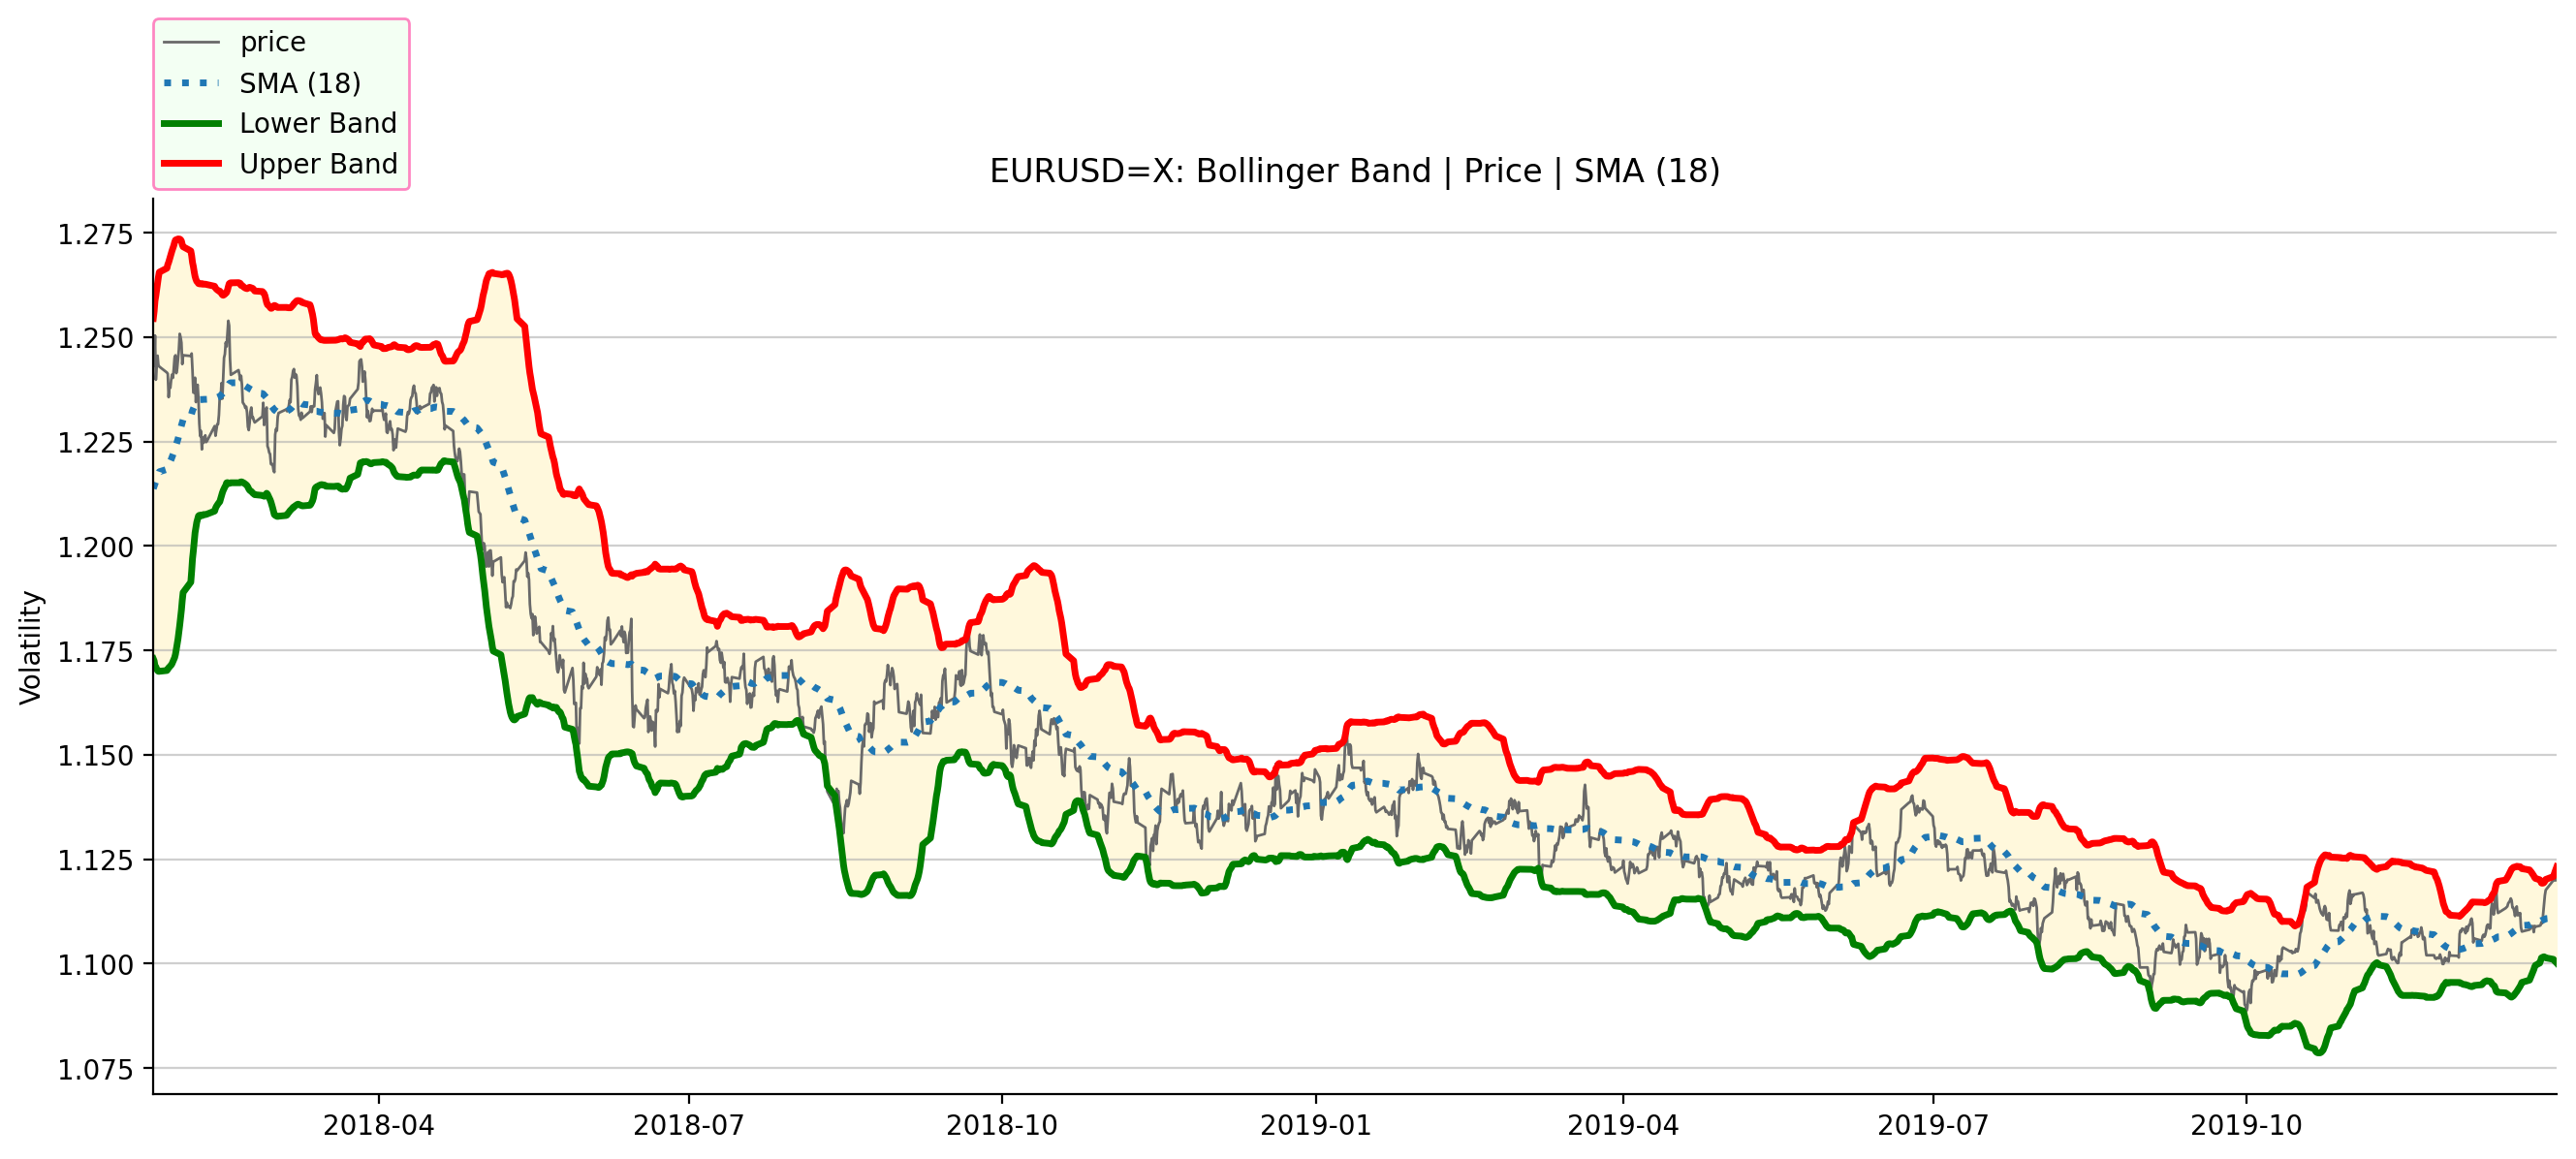

In [248]:
bb_tester.plot_results("Bollinger_Band")

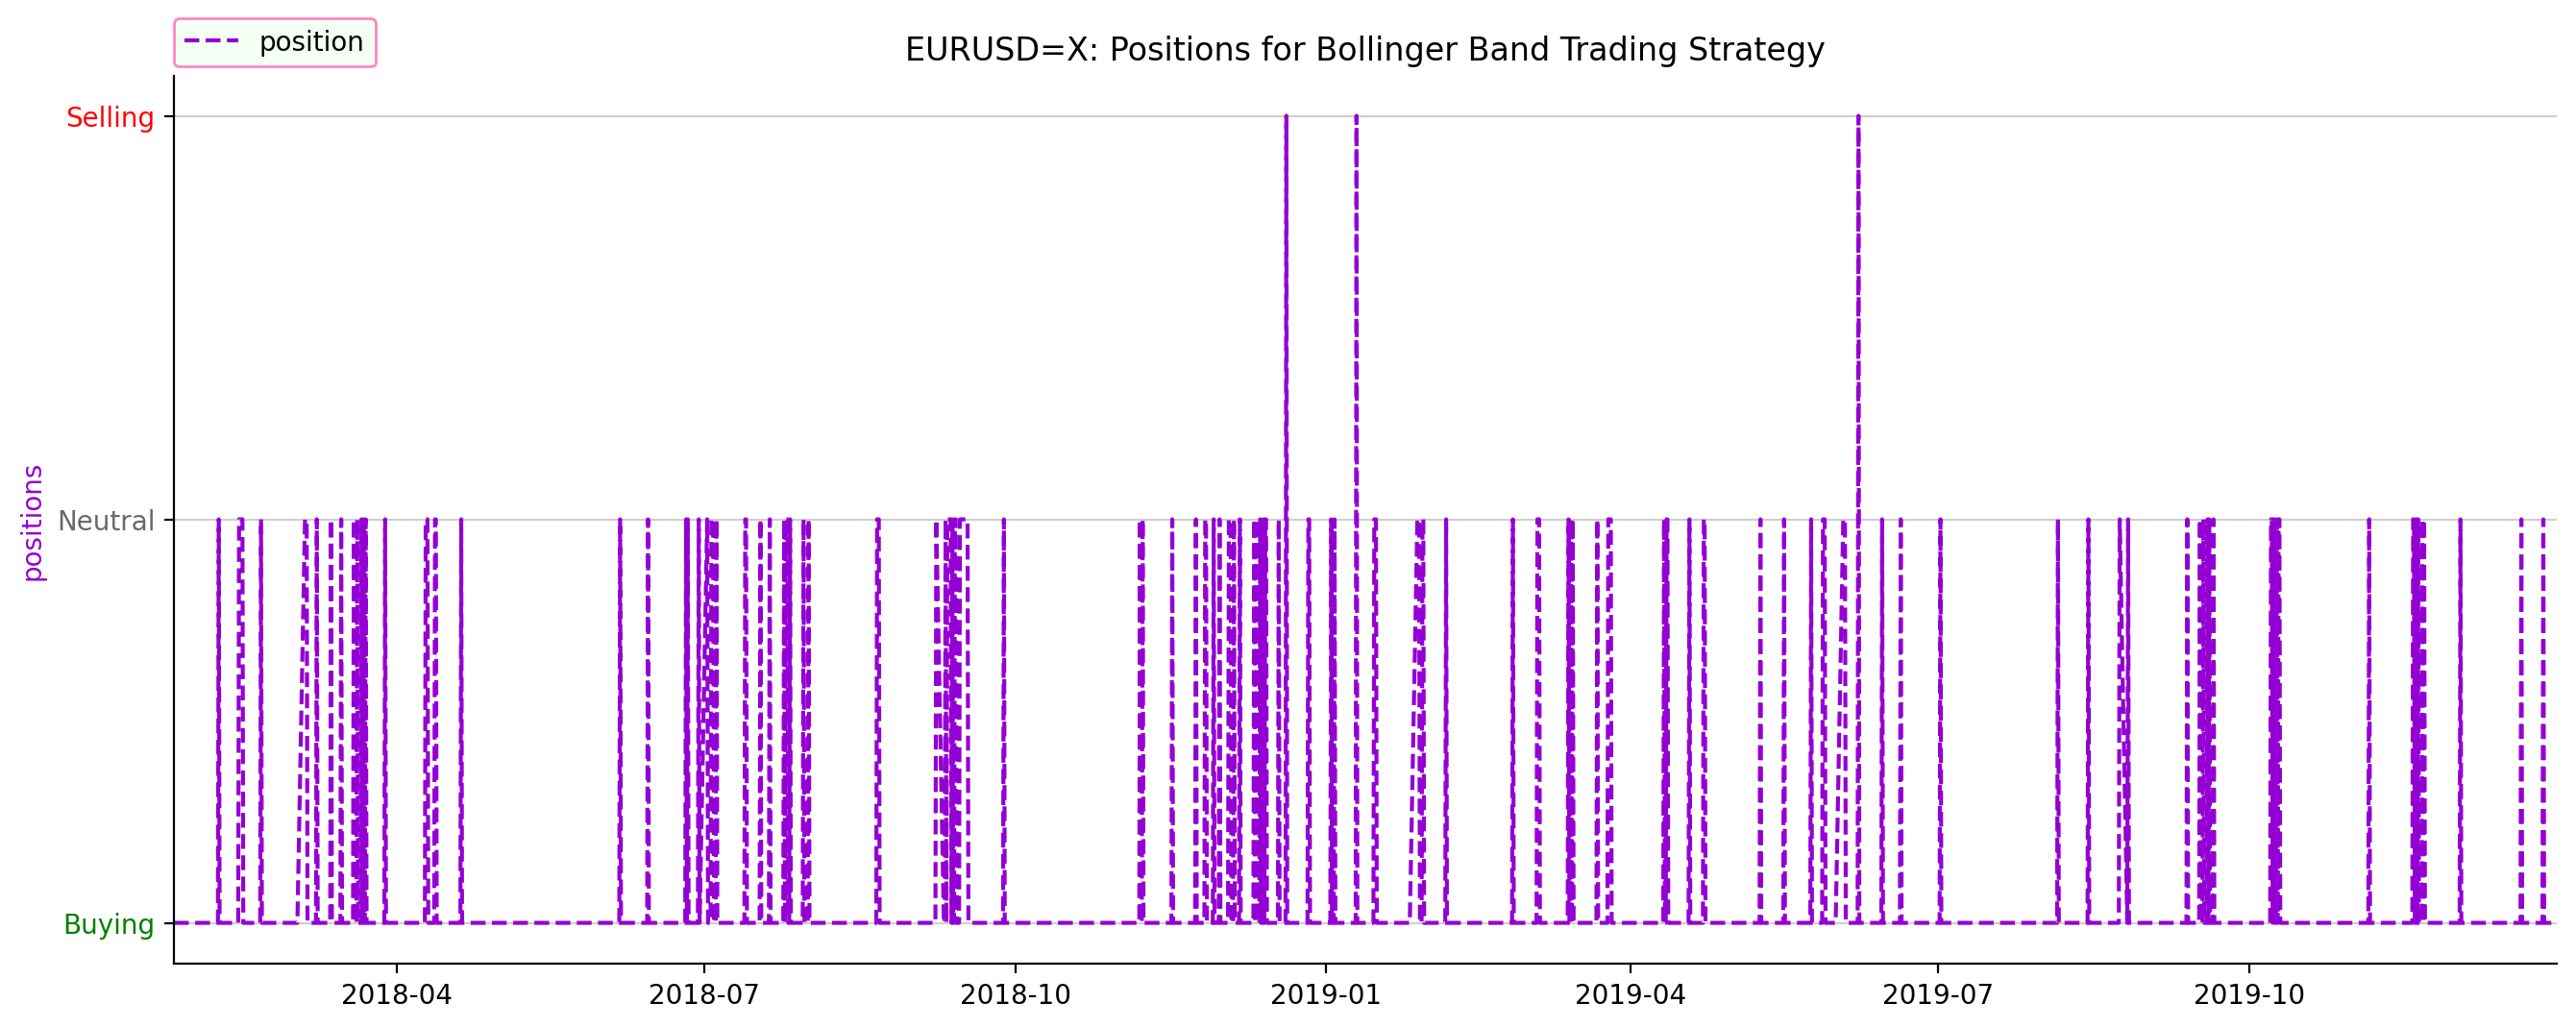

In [249]:
bb_tester.plot_results("position")

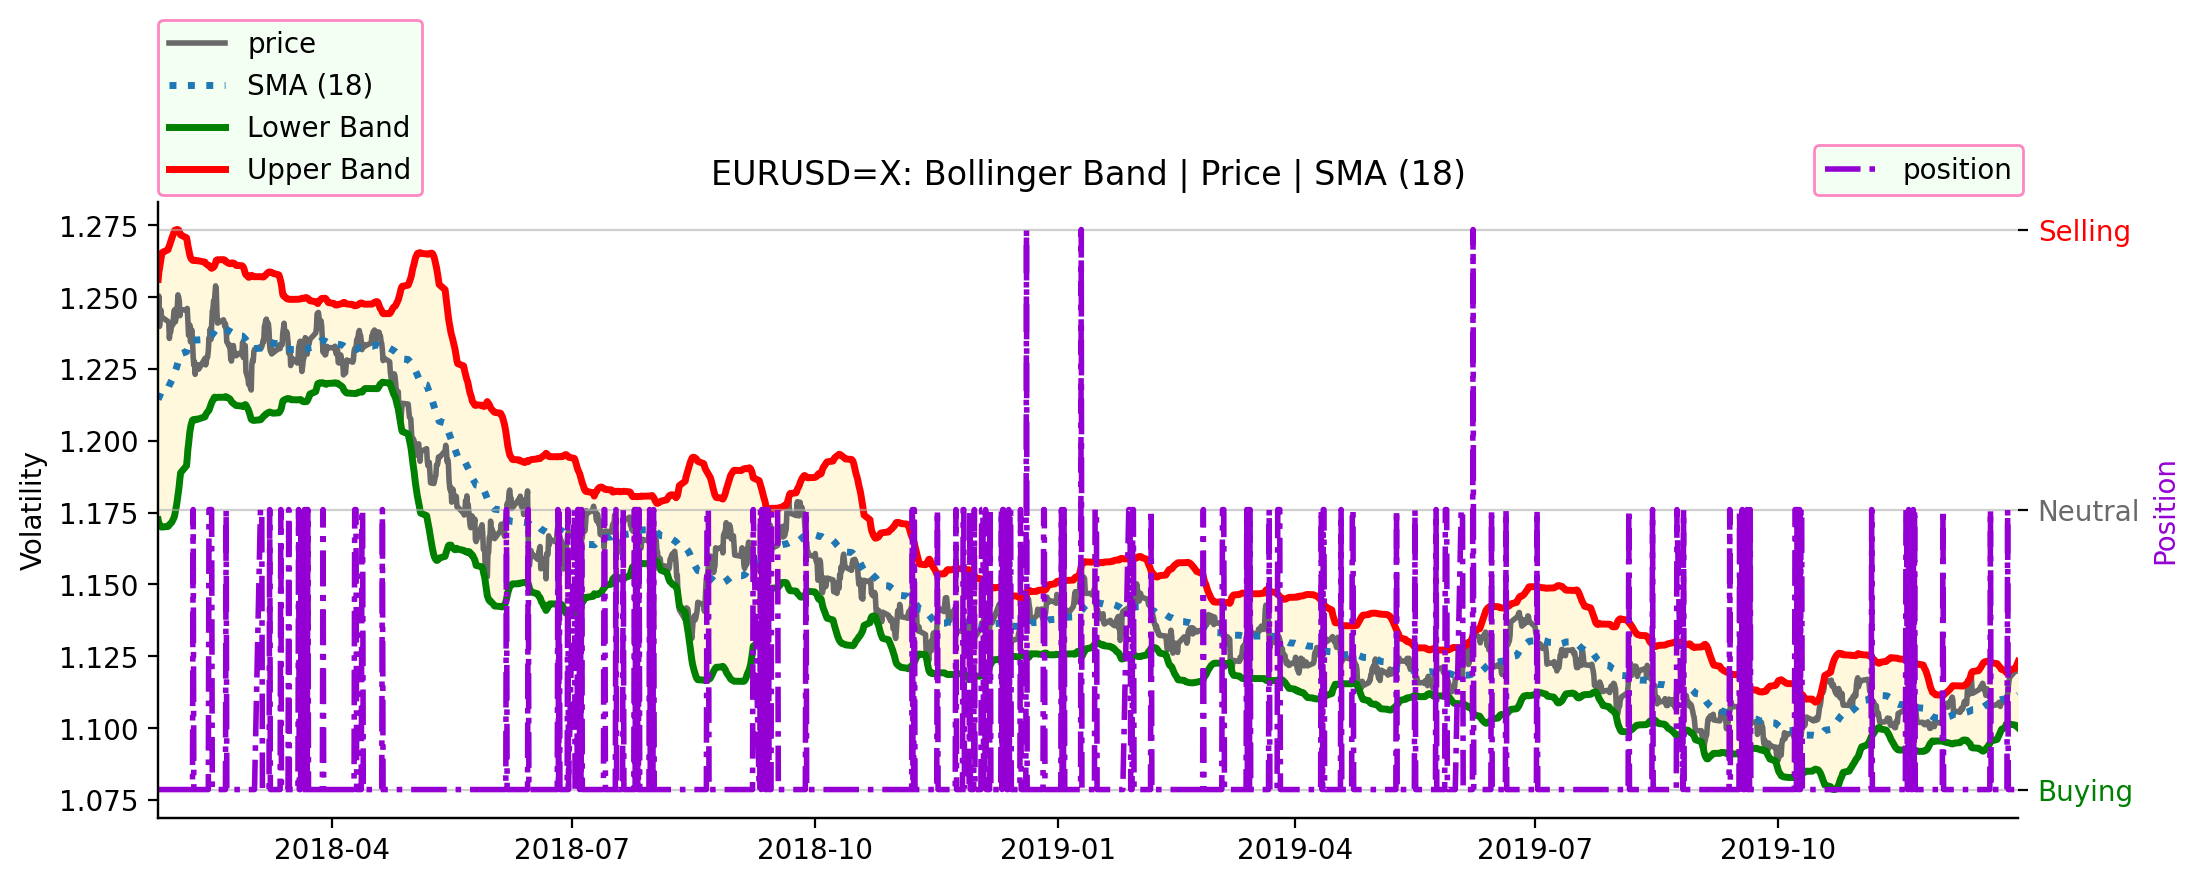

In [250]:
bb_tester.plot_results("Bollinger_Band_Position")

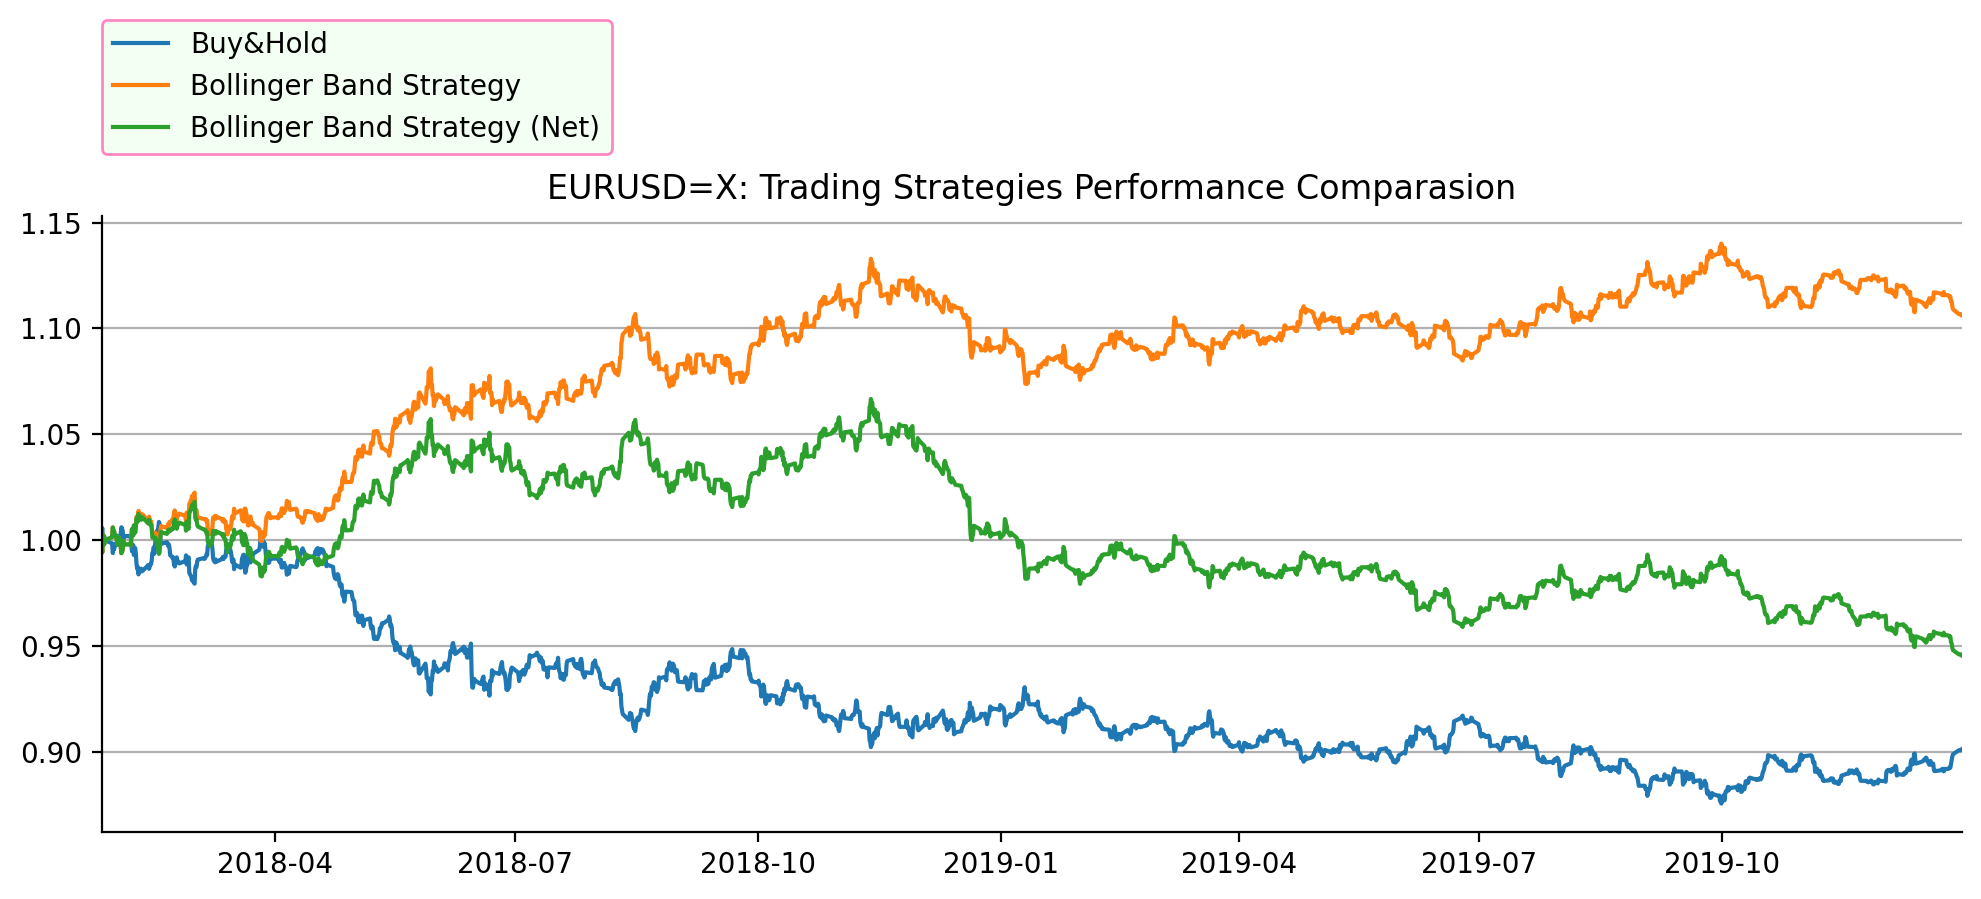

In [251]:
bb_tester.plot_results("trading_strategy")